# Extra experiment 1: rhythm features without the tempo

In the main experiment the rhythm models reach about 80% macro-F1 on the original audio, but they collapse when the music is played a bit faster or slower. The reason is that the cyclic tempogram we used still tells the model which tempo class a clip is in. So the main result says "our rhythm features mostly carry tempo", but not yet whether the rhythm pattern alone can tell the dances apart.

Here we remove the tempo from the rhythm features in two ways and run the same time-stretch test:

| Feature set | Inputs | What it is |
|---|---:|---|
| Rhythm (as before) | 20 | cyclic tempogram (15), bar ratios (3), PLP confidence and PLP alignment (2), same as the main notebooks |
| Tempo only | 1 | `tau_hat`, same as the main notebooks |
| Rhythm, tempo removed | 20 | the same, but the cyclic tempogram is shifted so that its strongest bin is always bin 0 |
| Scale transform | 20 | a rhythm descriptor that does not change when the music is stretched (Holzapfel & Stylianou, 2011) |
| Rhythm, tempo removed + tempo | 21 | the tempo-free rhythm set plus `tau_hat`, to see what happens when we give the tempo back |

The first two sets are the ones from the main notebooks. We run them again here as a reference and to check that the pipeline gives the same numbers.

Both classifiers (Random Forest and SVM-RBF), the folds, the tuning and the 13 audio versions are the same as in the main project.

The rhythm features use the updated settings of `src/Rythm_extraction.py` (see section 4 of the main rhythm notebooks), with a tempo range of 60–220 BPM.

> **Earlier run, kept for reference.** This run used the updated rhythm extraction with a tempo range of 60–220 BPM, the value set in `src/Rythm_extraction.py`. The main run now uses 60–280 BPM: with 220 BPM, fast dances stretched by +10% (for example Quickstep at about 204–211 BPM, which becomes 224–232 BPM) go over the limit and the tempo estimate is forced to jump. The notebook paths point to the main project folder, so this copy is a record and is not meant to be run from here.

## 1. Imports

In [1]:
from pathlib import Path
import platform
import time
import warnings

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.metrics import f1_score

import features as F
import evaluation as E

# librosa 1.0 warns about arguments it passes to itself inside time_stretch; harmless, so hidden
warnings.filterwarnings('ignore', message='The `(hop_length|n_fft)` parameter is deprecated', category=FutureWarning)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180})
pd.set_option('display.max_columns', 30)
display(pd.Series({'python': platform.python_version(), 'numpy': np.__version__,
                   'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
                   'librosa': librosa.__version__}, name='version').to_frame())

,version
python,3.12.13
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
librosa,1.0.0


## 2. Settings

`DATASET_DIR` is the only path you may need to change. The features of all 13 versions are saved in `all_versions_features.csv` the first time and reused after that, also by the other notebook in this folder.

In [2]:
DATASET_DIR = Path('../BallroomData')                  # the folder with the dance folders
FEATURES_PATH = Path('all_versions_features.csv')       # shared by both notebooks in this folder
MAIN_RESULTS_DIR = Path('../results')                   # results of the main notebooks, only used for checks
RESULTS_DIR = Path('results') / 'rhythm_without_tempo'

EXPECTED_CLIPS = 698
N_JOBS = 8                          # CPU cores; set to 1 if parallel runs give problems
MODEL_NAMES = list(E.MODELS)        # Random Forest and SVM-RBF

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


def save(table, name, **options):
    table.to_csv(RESULTS_DIR / name, **options)


def save_figure(figure, name):
    figure.savefig(RESULTS_DIR / name, bbox_inches='tight')
    plt.show()

## 3. Clips and folds

Same clips and same five test folds as the main notebooks: stratified by dance, and the 13 known duplicate pairs always stay in one fold. If the main results are there, we check that every clip is in the same fold as before, so the numbers can be compared directly.

In [3]:
clips = E.find_clips(DATASET_DIR)
class_labels = np.sort(clips['label'].unique())
assert len(clips) == EXPECTED_CLIPS and len(class_labels) == 8, f'found {len(clips)} clips in {DATASET_DIR}'

folds = E.make_folds(clips)
clips = clips.merge(folds[['filename', 'group_id', 'fold']], on='filename', validate='one_to_one')

main_folds = MAIN_RESULTS_DIR / 'rhythm_random_forest' / 'rhythm' / 'out_of_fold_predictions.csv'
if main_folds.is_file():
    before = pd.read_csv(main_folds).set_index('filename')['fold']
    assert (clips.set_index('filename')['fold'] == before.loc[clips['filename']]).all()
    print('every clip is in the same test fold as in the main notebooks')
display(pd.crosstab(clips['fold'], clips['label'], margins=True))

every clip is in the same test fold as in the main notebooks


label,ChaChaCha,Jive,Quickstep,Rumba,Samba,Tango,VienneseWaltz,Waltz,All
fold,,,,,,,,,
1,22,12,17,20,17,17,13,22,140
2,22,12,17,20,17,17,13,22,140
3,22,12,16,20,17,18,13,22,140
4,22,12,16,19,18,17,13,22,139
5,23,12,16,19,17,17,13,22,139
All,111,60,82,98,86,86,65,110,698


## 4. Features of all 13 versions

Every clip is used in 13 versions: the original, six stretches (−10%, −5%, −2%, +2%, +5%, +10%) and six round trips (stretched and stretched back, so the tempo is the original one again). The code is in `features.py`. The timbral and rhythm features there are the same code as in the main notebooks, and the shifted cyclic tempogram and the scale transform are new.

Computing everything takes about 15 minutes. If the run stops, starting the cell again continues where it stopped.

In [4]:
if F.is_complete(FEATURES_PATH, clips):
    print(f'using the saved features in {FEATURES_PATH}')
else:
    start = time.perf_counter()
    F.extract_all_versions(clips, DATASET_DIR, FEATURES_PATH, n_jobs=N_JOBS)
    print(f'computed in {(time.perf_counter() - start)/60:.1f} minutes')

versions = pd.read_csv(FEATURES_PATH)
feature_columns = F.TIMBRAL_COLUMNS + F.CYCLIC_COLUMNS + F.RATIO_COLUMNS + F.PLP_COLUMNS + ['tau_hat'] \
    + F.SHIFTED_COLUMNS + F.SCALE_COLUMNS
assert not versions.duplicated(['filename', 'condition']).any()
assert np.isfinite(versions[feature_columns].to_numpy(dtype=float)).all(), 'NaN or infinite values in the features'

# the training table: features of the original audio, with labels and folds
data = (versions[versions['condition'] == 'original']
        .merge(clips[['filename', 'group_id', 'fold']], on='filename', validate='one_to_one')
        .sort_values('filename').reset_index(drop=True))
print(f'{len(versions)} rows ({len(data)} clips x {len(F.CONDITIONS)} versions), {len(feature_columns)} feature columns')

0 clips already done, 698 to go (using 8 cores)


  25 of 698 clips


  50 of 698 clips


  75 of 698 clips


  100 of 698 clips


...

  625 of 698 clips


  650 of 698 clips


  675 of 698 clips


  698 of 698 clips


computed in 16.5 minutes
9074 rows (698 clips x 13 versions), 86 feature columns


## 5. The two tempo-free rhythm features

**Shifted cyclic tempogram.** The cyclic tempogram folds all tempi into one octave, so 60, 120 and 240 BPM land in the same bin. But the bins are still tied to fixed tempo classes, so the position of the strongest bin tells the tempo class, and a 10% stretch moves the whole profile by about 2 of its 15 bins. If we rotate the profile so that the strongest bin is always bin 0, the shape stays (which other pulse levels are there, relative to the main one) but the tempo class is gone. This is the `shift=True` option that was already in `Rythm_extraction.py`.

**Scale transform.** We take the autocorrelation of the novelty curve, which shows after which time lags the music repeats itself (one beat, two beats, one bar and so on). When the music is played faster, this curve is squeezed along the lag axis, but its shape stays the same. If the lag axis is logarithmic, the squeeze turns into a shift, and the magnitude of a Fourier transform does not change when its input is shifted. The scale transform does exactly this: for an autocorrelation $r(t)$ it computes

$$S(c) = \int_0^\infty r(t)\, t^{-jc - \frac{1}{2}}\, dt$$

and with $t = e^u$ this becomes a normal Fourier transform of $r(e^u)\,e^{u/2}$. We use lags between 0.1 s and 4 s on a log axis with 256 points and keep the magnitude of the first 20 coefficients, normalised to length 1. This is the same idea as the tempo-insensitive representation of Jensen et al. (2009) from our proposal.

Before training anything, we check how much each representation changes when the audio is stretched. All three vectors have length 1, so the dot product between the original and the changed version is their cosine similarity: 1 means unchanged.

representation,Cyclic tempogram (as before),Scale transform,Shifted cyclic tempogram
condition,,,
stretch_0.90,0.822,0.989,0.983
stretch_0.95,0.875,0.988,0.996
stretch_0.98,0.968,0.989,0.977
stretch_1.02,0.970,0.988,0.978
stretch_1.05,0.885,0.986,0.998
stretch_1.10,0.832,0.984,0.997
roundtrip_0.90,0.998,0.980,0.998
roundtrip_0.95,0.998,0.979,0.998
roundtrip_0.98,0.998,0.978,0.998


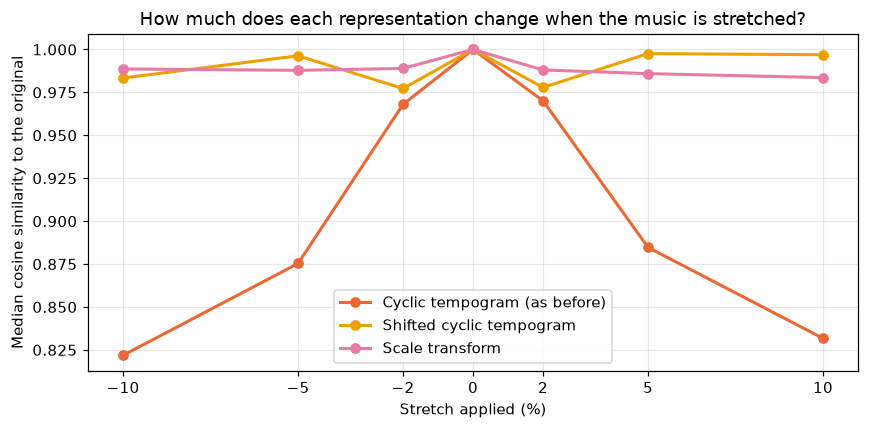

In [5]:
representations = {'Cyclic tempogram (as before)': F.CYCLIC_COLUMNS,
                   'Shifted cyclic tempogram': F.SHIFTED_COLUMNS,
                   'Scale transform': F.SCALE_COLUMNS}

original = versions[versions['condition'] == 'original'].set_index('filename')
rows = []
for condition, part in versions.groupby('condition'):
    part = part.set_index('filename').loc[original.index]
    for name, columns in representations.items():
        similarity = np.sum(part[columns].to_numpy()*original[columns].to_numpy(), axis=1)
        rows.append({'condition': condition, 'kind': part['kind'].iloc[0], 'rate': part['rate'].iloc[0],
                     'representation': name, 'median similarity': np.median(similarity),
                     'clips above 0.95 (%)': 100*np.mean(similarity > 0.95)})
similarity = pd.DataFrame(rows)
save(similarity, 'similarity_to_original.csv', index=False)

display(similarity[similarity['kind'] != 'original']
        .pivot_table(index='condition', columns='representation', values='median similarity')
        .loc[F.CONDITION_ORDER[1:]].round(3))

figure, axis = plt.subplots(figsize=(8, 4))
colors = ['#eb6834', '#eda100', '#e87ba4']
for (name, rows), color in zip(similarity.groupby('representation', sort=False), colors):
    rows = rows[rows['kind'].isin(['stretch', 'original'])].sort_values('rate')
    axis.plot(100*(rows['rate'] - 1), rows['median similarity'], marker='o', linewidth=2, color=color, label=name)
axis.set(xlabel='Stretch applied (%)', ylabel='Median cosine similarity to the original',
         title='How much does each representation change when the music is stretched?')
axis.set_xticks([-10, -5, -2, 0, 2, 5, 10])
axis.grid(alpha=0.3)
axis.legend()
figure.tight_layout()
save_figure(figure, 'similarity_to_original.png')

The cyclic tempogram as before changes a lot: at ±10% its median similarity drops to about 0.82-0.83. The shifted cyclic tempogram and the scale transform stay at about 0.98 or higher for every stretch, so on paper both are tempo-free.

Two details matter for the results below. First, the shifted tempogram changes a bit more at ±2% (0.98) than at +5% and +10% (above 0.99). The reason is the bin size. One bin is about 4.7% of tempo, so a 5% or 10% stretch moves the profile by almost a whole number of bins (1.06 and 2.06), and the rotation removes that completely. A 2% stretch moves it by about half a bin, and that changes the shape of the profile. Second, the scale transform changes more after a round trip than after a stretch, so it reacts to the processing itself and not only to the tempo.

## 6. The feature sets

In [6]:
RHYTHM_COLUMNS = F.CYCLIC_COLUMNS + F.RATIO_COLUMNS + F.PLP_COLUMNS
TEMPO_FREE_COLUMNS = F.SHIFTED_COLUMNS + F.RATIO_COLUMNS + F.PLP_COLUMNS

FEATURE_SETS = {
    'Rhythm (as before)': RHYTHM_COLUMNS,
    'Tempo only': ['tau_hat'],
    'Rhythm, tempo removed': TEMPO_FREE_COLUMNS,
    'Scale transform': F.SCALE_COLUMNS,
    'Rhythm, tempo removed + tempo': TEMPO_FREE_COLUMNS + ['tau_hat'],
}
display(pd.Series({name: len(columns) for name, columns in FEATURE_SETS.items()}, name='inputs').to_frame())

,inputs
Rhythm (as before),20
Tempo only,1
"Rhythm, tempo removed",20
Scale transform,20
"Rhythm, tempo removed + tempo",21


## 7. Training

For every feature set and both classifiers we run the same nested cross-validation as the main notebooks: for each of the five test folds, a default model and a tuned model (grid search on three inner folds) are trained on the other four folds, using the original audio only. The grids are the ones from the rhythm notebooks. This cell takes a few minutes.

In [7]:
cv = {}
for model_name in MODEL_NAMES:
    for set_name, columns in FEATURE_SETS.items():
        print(f'{model_name}, {set_name} ({len(columns)} inputs)')
        cv[model_name, set_name] = E.run_nested_cv(data, columns, model_name, n_jobs=N_JOBS)

fold_metrics = pd.concat([result.fold_metrics.assign(model=model_name, feature_set=set_name)
                          for (model_name, set_name), result in cv.items()], ignore_index=True)
best_parameters = pd.concat([result.best_parameters.assign(model=model_name, feature_set=set_name)
                             for (model_name, set_name), result in cv.items()], ignore_index=True)
save(fold_metrics, 'fold_metrics.csv', index=False)
save(best_parameters, 'best_parameters.csv', index=False)

Random Forest, Rhythm (as before) (20 inputs)


    tuned macro-F1 per fold: 0.842, 0.767, 0.834, 0.816, 0.837


Random Forest, Tempo only (1 inputs)


    tuned macro-F1 per fold: 0.620, 0.634, 0.670, 0.619, 0.587


Random Forest, Rhythm, tempo removed (20 inputs)


...

    tuned macro-F1 per fold: 0.703, 0.635, 0.627, 0.602, 0.602


SVM-RBF, Scale transform (20 inputs)


    tuned macro-F1 per fold: 0.783, 0.706, 0.700, 0.673, 0.723


SVM-RBF, Rhythm, tempo removed + tempo (21 inputs)


    tuned macro-F1 per fold: 0.790, 0.700, 0.686, 0.726, 0.714


## 8. Results on the original audio

Mean ± SD over the five test folds, tuned models. The first two rows should give the same numbers as the main rhythm notebooks; the next cell checks this against their saved results.

In [8]:
tuned = fold_metrics[fold_metrics['variant'] == 'Tuned']
summary = E.summarize_folds(tuned, ['accuracy', 'macro_f1'], by=('feature_set', 'model'))
save(summary, 'metric_summary.csv', index=False)

table = pd.DataFrame({model_name: [f'{100*m:.1f} ± {100*s:.1f}' for m, s in
                                   zip(rows['macro_f1_mean'], rows['macro_f1_std'])]
                      for model_name, rows in summary.groupby('model', sort=False)},
                     index=summary['feature_set'].unique())
table.index.name = 'macro-F1 (%)'
display(table)

,Random Forest,SVM-RBF
macro-F1 (%),,
Rhythm (as before),81.9 ± 3.1,82.7 ± 3.0
Tempo only,62.6 ± 3.0,64.7 ± 3.0
"Rhythm, tempo removed",64.3 ± 3.5,63.4 ± 4.1
Scale transform,69.2 ± 5.0,71.7 ± 4.1
"Rhythm, tempo removed + tempo",79.8 ± 2.5,72.3 ± 4.0


In [9]:
# the two reference sets against the saved results of the main notebooks
main_dirs = {('Random Forest', 'Rhythm (as before)'): 'rhythm_random_forest/rhythm',
             ('Random Forest', 'Tempo only'): 'rhythm_random_forest/tempo_only',
             ('SVM-RBF', 'Rhythm (as before)'): 'rhythm_svm_rbf/rhythm',
             ('SVM-RBF', 'Tempo only'): 'rhythm_svm_rbf/tempo_only'}
rows = []
for (model_name, set_name), folder in main_dirs.items():
    path = MAIN_RESULTS_DIR / folder / 'metric_summary.csv'
    if path.is_file():
        before = pd.read_csv(path).set_index('variant').loc['Tuned', 'macro_f1_mean']
        now = summary.set_index(['feature_set', 'model']).loc[(set_name, model_name), 'macro_f1_mean']
        rows.append({'model': model_name, 'feature set': set_name, 'main notebooks (%)': 100*before,
                     'here (%)': 100*now, 'difference (pp)': 100*(now - before)})
display(pd.DataFrame(rows).round(2) if rows else 'main results not found, check skipped')

,model,feature set,main notebooks (%),here (%),difference (pp)
0,Random Forest,Rhythm (as before),81.91,81.91,0.0
1,Random Forest,Tempo only,62.59,62.59,0.0
2,SVM-RBF,Rhythm (as before),82.66,82.66,0.0
3,SVM-RBF,Tempo only,64.66,64.66,0.0


The two reference sets give exactly the same numbers as the main rhythm notebooks, which use the same features.

Removing the tempo costs a lot here. Without the tempo, the rhythm set gets 63-64% instead of 82-83%, and the scale transform gets 69-72%. The tempo-free rhythm set is about as good as the tempo-only baseline (63-65%), and the scale transform is better. Both are far above chance (12.5%), so the rhythm pattern alone does carry information about the dance.

When we give the tempo back (last row), the Random Forest goes up to 80%, close to the original rhythm set. The SVM only reaches 72%.

## 9. Results on the stretched audio

The fold models from the training section are used as they are; only `.predict()` is called on the features of the changed audio. For every model and feature set:

- the macro-F1 on the original audio and at −10% and +10%,
- the mean change over the six stretches and over the six round trips,
- "caused by tempo": the stretch change minus the round-trip change, the same measure as in the main README,
- the flip rate: the share of clips whose prediction changes when the audio is stretched.

The figure shows the tuned models. Left: stretched audio; right: round trip.

In [10]:
condition_metrics, held_out = {}, []
for (model_name, set_name), result in cv.items():
    metrics, predictions = E.evaluate_conditions(result, data, versions, F.CONDITIONS)
    condition_metrics[model_name, set_name] = metrics.assign(model=model_name, feature_set=set_name)
    held_out.append(predictions.assign(model=model_name, feature_set=set_name))

all_condition_metrics = pd.concat(condition_metrics.values(), ignore_index=True)
save(all_condition_metrics, 'stretch_fold_metrics.csv', index=False)
save(pd.concat(held_out, ignore_index=True), 'held_out_predictions_tuned.csv', index=False)

robustness = E.summarize_folds(all_condition_metrics, ['accuracy', 'macro_f1', 'flip_rate', 'macro_f1_change_pp'],
                               by=('model', 'feature_set', 'variant', 'condition', 'kind', 'rate', 'tempo_change_percent'))
save(robustness, 'robustness_summary.csv', index=False)

tempo_effect = pd.DataFrame([{'model': model_name, 'feature set': set_name, **E.tempo_effect_row(metrics)}
                             for (model_name, set_name), metrics in condition_metrics.items()])
tempo_effect = tempo_effect.set_index(['model', 'feature set'])
save(tempo_effect, 'tempo_effect.csv')
display(tempo_effect.round(1))

original macro-F1 (%)  \
model         feature set                                            
Random Forest Rhythm (as before)                              81.9   
              Tempo only                                      62.6   
              Rhythm, tempo removed                           64.3   
              Scale transform                                 69.2   
              Rhythm, tempo removed + tempo                   79.8   
SVM-RBF       Rhythm (as before)                              82.7   
              Tempo only                                      64.7   
              Rhythm, tempo removed                           63.4   
              Scale transform                                 71.7   
              Rhythm, tempo removed + tempo                   72.3   

                                             at -10% (%)  at +10% (%)  \
model         feature set                                               
Random Forest Rhythm (as before)                    21.6         15.1   
              Tempo only                            20.7         12.6   
              Rhythm, tempo removed                 38.6         44.1   
              Scale transform                       51.1         46.0   
              Rhythm, tempo removed + tempo         34.0         28.2   
SVM-RBF       Rhythm (as before)                    33.2         15.9   
              Tempo only                            11.9         11.9   
              Rhythm, tempo removed                 39.2         48.9   
              Scale transform                       54.0         46.8   
              Rhythm, tempo removed + tempo         45.4         52.5   

                                             mean change, stretch (pp)  \
model         feature set                                                
Random Forest Rhythm (as before)                                 -39.1   
              Tempo only                                         -35.2   
              Rhythm, tempo removed                              -18.2   
              Scale transform                                    -22.1   
              Rhythm, tempo removed + tempo                      -32.0   
SVM-RBF       Rhythm (as before)                                 -38.9   
              Tempo only                                         -40.0   
              Rhythm, tempo removed                              -15.2   
              Scale transform                                    -20.2   
              Rhythm, tempo removed + tempo                      -16.3   

                                             mean change, round trip (pp)  \
model         feature set                                                   
Random Forest Rhythm (as before)                                    -11.9   
              Tempo only                                             -4.2   
              Rhythm, tempo removed                                 -18.5   
              Scale transform                                       -31.6   
              Rhythm, tempo removed + tempo                         -16.9   
SVM-RBF       Rhythm (as before)                                    -12.2   
              Tempo only                                             -2.7   
              Rhythm, tempo removed                                 -11.2   
              Scale transform                                       -29.2   
              Rhythm, tempo removed + tempo                         -13.1   

                                             caused by tempo (pp)  \
model         feature set                                           
Random Forest Rhythm (as before)                            -27.1   
              Tempo only                                    -30.9   
              Rhythm, tempo removed                           0.3   
              Scale transform                                 9.5   
              Rhythm, tempo removed + tempo                 -15.1   
SVM-RBF       Rhythm (as befor

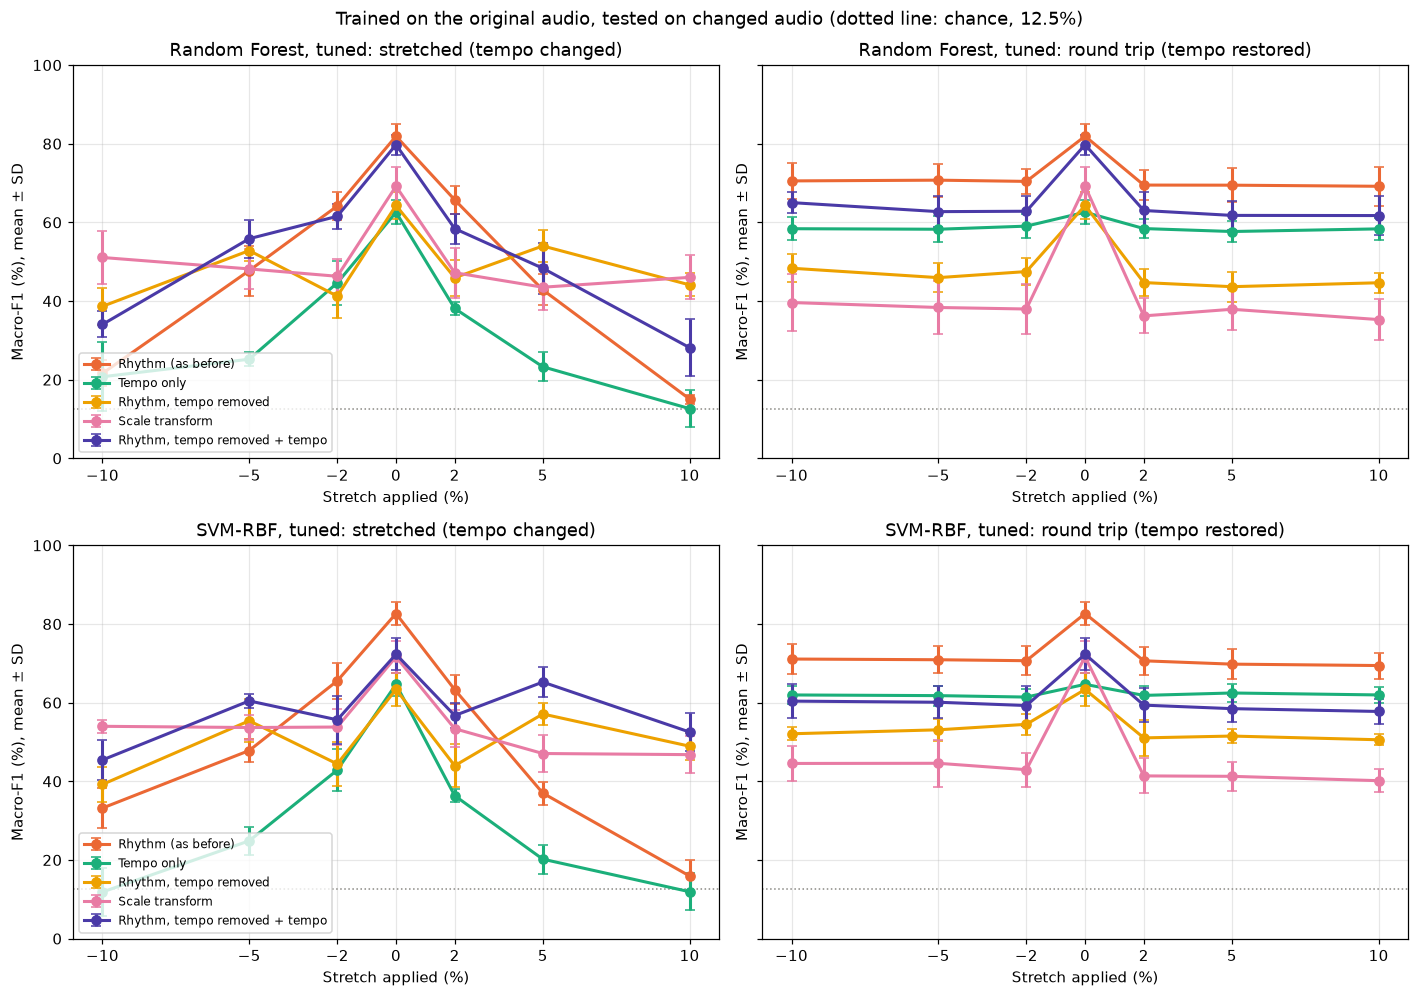

In [11]:
figure, axes = plt.subplots(len(MODEL_NAMES), 2, figsize=(13, 4.6*len(MODEL_NAMES)), sharey=True)
for row, model_name in enumerate(MODEL_NAMES):
    curves = {set_name: condition_metrics[model_name, set_name] for set_name in FEATURE_SETS}
    E.plot_robustness(curves, {name: E.SET_COLORS[name] for name in FEATURE_SETS}, model_name, axes[row])
figure.suptitle('Trained on the original audio, tested on changed audio (dotted line: chance, 12.5%)')
figure.tight_layout()
save_figure(figure, 'robustness_curves.png')

Rhythm, tempo removed: the part of the drop that comes from the tempo is close to zero (+0.3 and −4.0 points), against −27 points for the rhythm set as before. But this is partly because the round trip already hurts this model a lot (−11 to −19 points): with these settings the tempo-free rhythm features react to the stretching itself. At +10% the models still get 44-49%, while the original rhythm set falls to 15-16%. The dip at ±2% from section 5 is still there (41-46%).

Scale transform: these features don't use the changed rhythm code, so the results are the same as in the earlier run. The curve under stretching is flat (46-54%), and the round trip is even worse than the stretch, so the tempo itself does not matter for this model. But it loses 20-30 points as soon as the audio goes through the phase vocoder at all.

Rhythm, tempo removed + tempo: with the tempo back, the Random Forest becomes fragile again (−15 points caused by the tempo, 28% at +10%). The SVM uses the tempo less and stays at 53% at +10%.

## 10. Which dances can be recognised without the tempo?

F1 per dance on the original audio (tuned Random Forest), for the rhythm set as before, the tempo-only set and the two tempo-free sets.

In [12]:
per_genre = {}
for set_name in ['Rhythm (as before)', 'Tempo only', 'Rhythm, tempo removed', 'Scale transform']:
    predictions = cv['Random Forest', set_name].predictions
    per_genre[set_name] = pd.Series(f1_score(predictions['label'], predictions['prediction_tuned'],
                                            labels=class_labels, average=None), index=class_labels)
per_genre = 100*pd.DataFrame(per_genre)
save(per_genre, 'per_genre_f1_random_forest.csv')
display(per_genre.round(1))

,Rhythm (as before),Tempo only,"Rhythm, tempo removed",Scale transform
ChaChaCha,89.8,72.3,73.4,82.9
Jive,76.3,54.7,53.8,65.0
Quickstep,78.8,51.7,54.3,71.6
Rumba,74.9,56.3,63.9,60.2
Samba,78.3,46.2,58.1,87.6
Tango,89.3,72.5,66.7,71.4
VienneseWaltz,83.3,74.8,80.0,54.8
Waltz,84.3,73.5,64.2,61.9


The two tempo-free features are good at different dances. With the shifted tempogram, VienneseWaltz stays high (80%), but Jive and Quickstep drop to 54%: these were dances that the tempo identified well. The scale transform is strongest on Samba (88%) and ChaChaCha (83%) but weak on VienneseWaltz (55%). So the two features seem to capture different parts of the rhythm.

## 11. What does the model use when it gets the tempo back?

Group permutation importance for "Rhythm, tempo removed + tempo" (tuned models): we shuffle one family of inputs across the test clips and measure how much macro-F1 drops. A big drop means the model relies on that family.

In [13]:
groups = {'Shifted cyclic tempogram': F.SHIFTED_COLUMNS, 'Bar ratios': F.RATIO_COLUMNS,
          'PLP': F.PLP_COLUMNS, 'Tempo (tau_hat)': ['tau_hat']}
importance = pd.concat({model_name: 100*E.group_importance(cv[model_name, 'Rhythm, tempo removed + tempo'], data, groups)
                        for model_name in MODEL_NAMES}, axis=1)
importance.columns = [f'{model} {stat} (pp)' for model, stat in importance.columns]
save(importance, 'importance_tempo_free_plus_tempo.csv')
display(importance.round(1))

,Random Forest mean (pp),Random Forest std (pp),SVM-RBF mean (pp),SVM-RBF std (pp)
feature_family,,,,
Tempo (tau_hat),50.6,2.4,19.0,2.8
Shifted cyclic tempogram,26.3,8.4,39.9,4.4
PLP,16.0,1.9,18.5,1.7
Bar ratios,2.3,1.3,6.5,1.0


The Random Forest relies on `tau_hat` much more than on the shifted tempogram (51 and 26 points), so as soon as the tempo is available, it uses it again. The SVM leans more on the shifted tempogram (40 points) than on the tempo (19 points), which fits its smaller drop under stretching. The two PLP inputs matter more than in the earlier run (16-19 points, mostly because of the new PLP alignment), and the bar ratios matter little (2-7 points).

## 12. Summary

- The rhythm pattern alone recognises the dances well above chance: 63-64% with the shifted cyclic tempogram and 69-72% with the scale transform, against 82-83% with the tempo included and 63-65% for the tempo alone.
- Without the tempo the shortcut is gone: the drop caused by the tempo is between +0.3 and −4 points instead of −27. But with these settings the tempo-free rhythm features are sensitive to the stretching itself (−11 to −19 points in the round trip).
- The scale transform does not react to the tempo at all, but it reacts strongly to the time-stretching artifacts. So "invariant on paper" is not the same as "robust in practice".
- When the tempo is added back, the Random Forest uses it again and becomes fragile again.